#### Objective:
#### To perform Preprocessing and visualization on loan application data using Python to understand applicant characteristics, analyze loan approval 
#### and rejection patterns, identify potential outliers, and explore relationships between financial features and loan status.

In [29]:
# Import NumPy for numerical operations, Pandas for data handling, Matplotlib for plotting, and Seaborn for statistical visualizations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the loan approval dataset from the CSV file into a DataFrame named df.

df=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Data Science & Data Analytics Project Folder\Python\Python Project\loan_approval_dataset.csv")

In [3]:
# Display the first five rows to preview the dataset and check the column names and sample values.

df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
# Check the number of rows and columns in the dataset.

df.shape

(4269, 13)

In [5]:
# Count missing values in each column to assess data completeness.

df.isnull().sum()

loan_id                      0
no_of_dependents             0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [6]:
# Count fully duplicated rows to check whether duplicate records are present.

df.duplicated().sum()

np.int64(0)

In [7]:
# Record the initial data-quality finding: the checks above found no missing values or duplicate rows.

In [8]:
# Count the distinct values in each column to understand the variety of values and spot possible unexpected categories.

df.nunique()

loan_id                      4269
no_of_dependents                6
 education                      2
 self_employed                  2
 income_annum                  98
 loan_amount                  378
 loan_term                     10
 cibil_score                  601
 residential_assets_value     278
 commercial_assets_value      188
 luxury_assets_value          379
 bank_asset_value             146
 loan_status                    2
dtype: int64

In [9]:
# Review each column's data type and non-null count to understand the dataset structure.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1   no_of_dependents           4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 531.6 KB


In [10]:
# Display the original column names before standardizing them.

df.columns

Index(['loan_id', 'no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='str')

In [11]:
# Remove leading and trailing spaces from column names to make them easier and safer to reference in code.
# Display the cleaned column names to verify the change.

df.columns = df.columns.str.strip()
df.columns

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='str')

In [12]:
# Select columns with numeric data types for numerical summaries, charts, and correlation analysis.

numcols = df.select_dtypes(include='number')
numcols

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,1,2,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,2,0,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,3,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,4,3,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,5,9800000,24200000,20,382,12400000,8200000,29400000,5000000
...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,1000000,2300000,12,317,2800000,500000,3300000,800000
4265,4266,0,3300000,11300000,20,559,4200000,2900000,11000000,1900000
4266,4267,2,6500000,23900000,18,457,1200000,12400000,18100000,7300000
4267,4268,1,4100000,12800000,8,780,8200000,700000,14100000,5800000


In [13]:
# Select columns with string/text data types for categorical summaries.

strcols=df.select_dtypes(include='str')
strcols

,education,self_employed,loan_status
0,Graduate,No,Approved
1,Not Graduate,Yes,Rejected
2,Graduate,No,Rejected
3,Graduate,No,Rejected
4,Not Graduate,Yes,Rejected
...,...,...,...
4264,Graduate,Yes,Rejected
4265,Not Graduate,Yes,Approved
4266,Not Graduate,No,Rejected
4267,Not Graduate,No,Approved


In [14]:
# Loop through each text column and print its value counts to inspect the distribution of categories.

for i in strcols:
    print(f"We are checking {i} column =====")
    print(df[i].value_counts())

We are checking education column =====
education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64
We are checking self_employed column =====
self_employed
Yes    2150
No     2119
Name: count, dtype: int64
We are checking loan_status column =====
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [15]:
# Calculate descriptive statistics for numeric columns, such as count, mean, standard deviation, quartiles, minimum, and maximum.

df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [16]:
# Summarize categorical columns, including the number of unique values and the most frequent category.

strcols.describe()

,education,self_employed,loan_status
count,4269,4269,4269
unique,2,2,2
top,Graduate,Yes,Approved
freq,2144,2150,2656


---------------Histogram for column no_of_dependents is -------


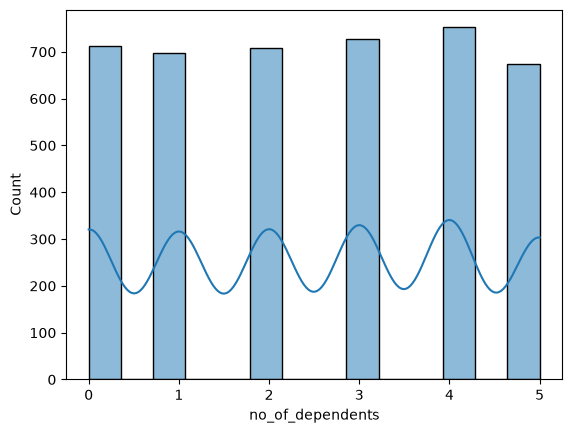

---------------Histogram for column income_annum is -------


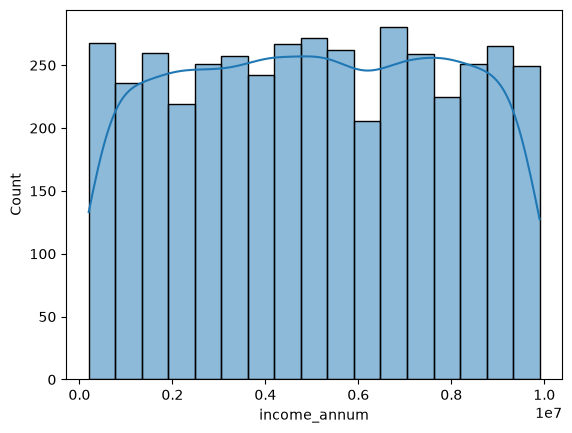

---------------Histogram for column loan_amount is -------


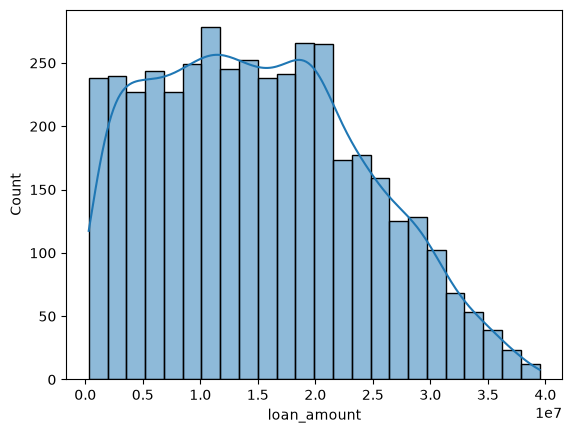

---------------Histogram for column loan_term is -------


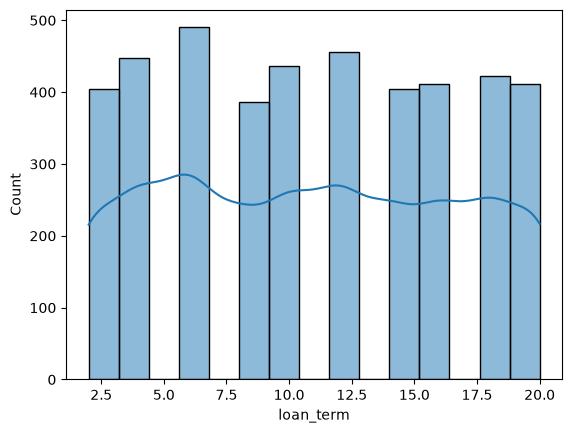

---------------Histogram for column cibil_score is -------


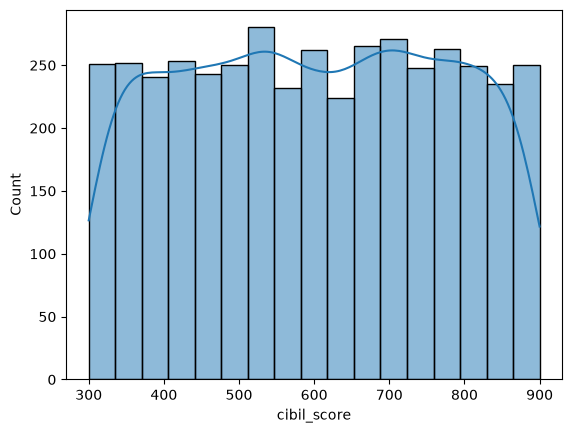

---------------Histogram for column residential_assets_value is -------


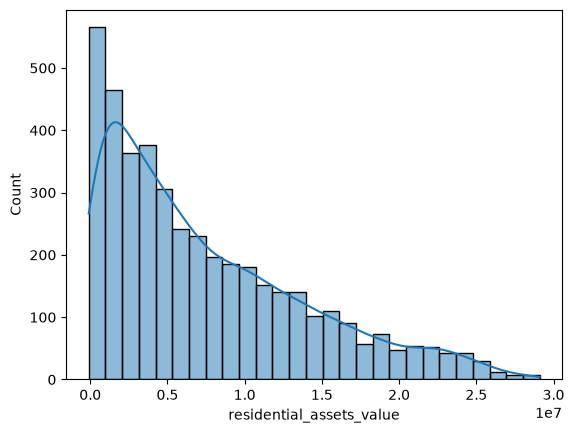

---------------Histogram for column commercial_assets_value is -------


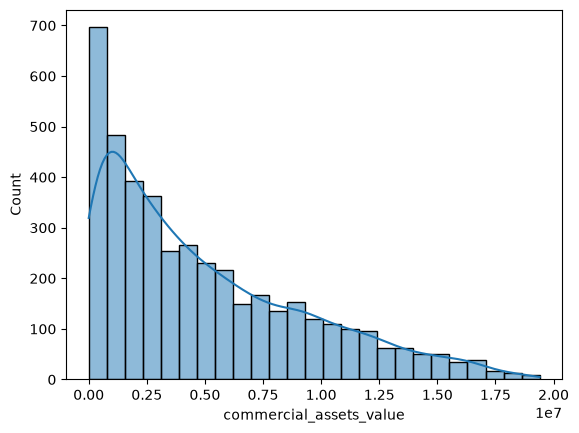

---------------Histogram for column luxury_assets_value is -------


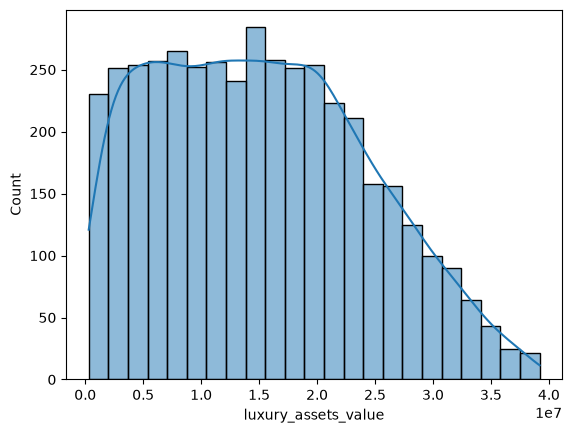

---------------Histogram for column bank_asset_value is -------


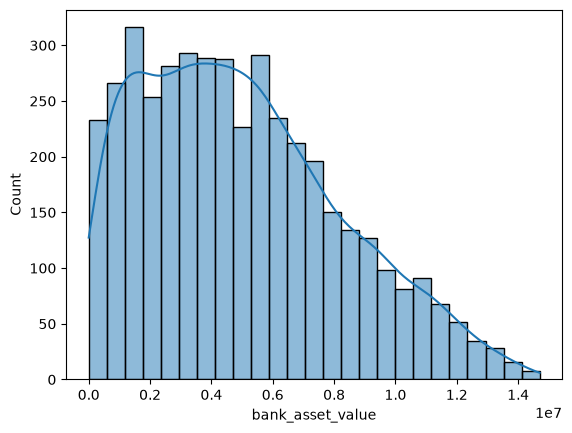

In [17]:
# Draw a histogram with a KDE curve for each numeric column except loan_id to inspect its distribution and possible skewness.

for i in numcols.drop(columns=['loan_id'], errors='ignore'):
    print(f"---------------Histogram for column {i} is -------")
    sns.histplot(df[i], kde=True)
    plt.show()

In [18]:
# Graph 1: Number of Dependents
# Applicants are distributed fairly evenly across 0–5 dependents,
# with 4 dependents being the most common and 5 the least common.

# Graph 2: Annual Income
# Annual income is distributed relatively evenly across the observed range,
# with no single income range dominating the distribution.

# Graph 3: Loan Amount
# Most loan amounts fall below approximately 2 crore, and the frequency
# decreases as loan amounts increase beyond this level.

# Graph 4: Loan Term
# Loan terms are spread across the observed range, with 6 years being
# the most frequent term and 20 years being among the least frequent.

# Graph 5: CIBIL Score
# CIBIL scores are distributed relatively evenly across the range of
# approximately 300–900, with no single score range dominating.

# Graph 6: Residential Asset Value
# Residential asset values are concentrated at the lower end,
# with fewer applicants reporting higher-value residential assets.

# Graph 7: Commercial Asset Value
# Commercial asset values are concentrated at lower values,
# with frequency decreasing as asset value increases.

# Graph 8: Luxury Asset Value
# Luxury asset values are more frequent in the lower-to-middle range,
# with fewer applicants having values above approximately 2 crore.

# Graph 9: Bank Asset Value
# Bank asset values are concentrated at lower values, and the frequency
# generally decreases as asset value increases.

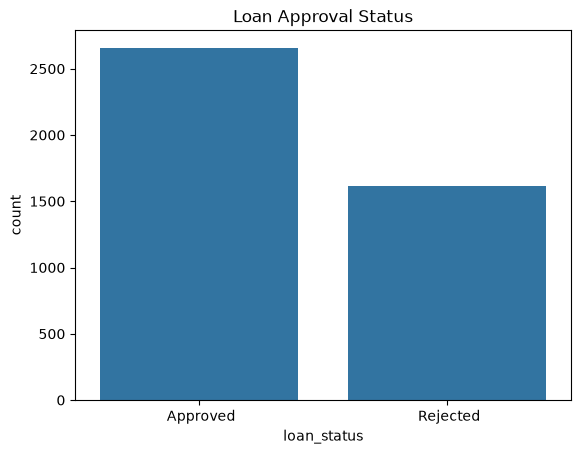

In [19]:
# Plot the number of applications in each loan_status category to compare approved and rejected applications.

sns.countplot(data=df, x='loan_status')
plt.title('Loan Approval Status')
plt.show()

In [20]:
# Conclusion of count plot-:
# The count plot shows the distribution of approved and rejected loan applications. Out of 4,269 applications, 2,656 (62.22%) were approved 
# and 1,613 (37.78%) were rejected. Therefore, approved applications account for the larger share of the dataset. 
# This chart provides an overview of the target variable for further analysis.

----------- Box plot for outlier detection: income_annum ---------


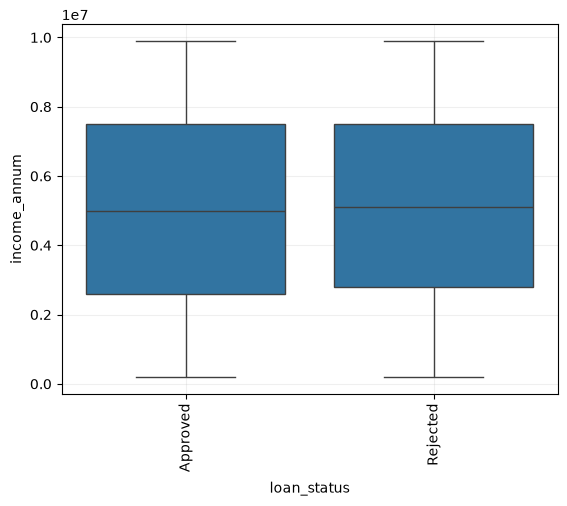

----------- Box plot for outlier detection: loan_amount ---------


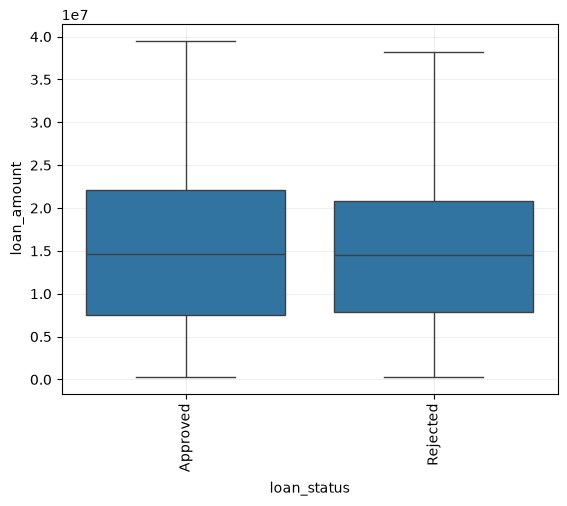

----------- Box plot for outlier detection: cibil_score ---------


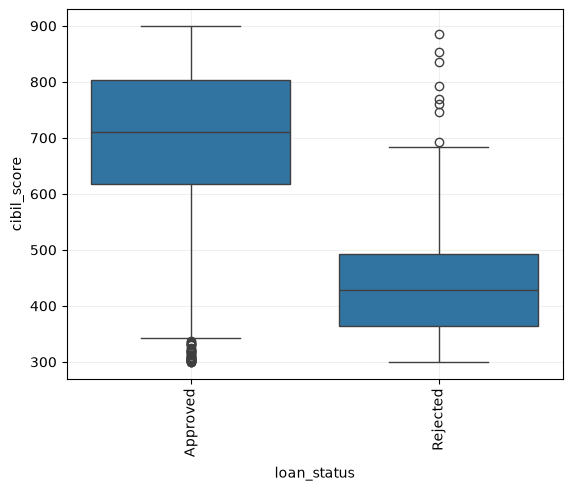

In [21]:
# Compare income, loan amount, and CIBIL score distributions by loan status using box plots.
# Points beyond the whiskers are potential statistical outliers and should be investigated, not automatically assumed to be errors.

cols = ['income_annum', 'loan_amount', 'cibil_score']

for i in cols:
    print(f"----------- Box plot for outlier detection: {i} ---------")
    sns.boxplot(x=df['loan_status'], y=df[i], data=df)
    plt.xticks(rotation=90)
    plt.grid(alpha=0.2)
    plt.show()

In [22]:
# Graph 1: Annual Income vs Loan Status
# The median annual income is very similar for approved and rejected applicants, at approximately 5 million. Both groups also show a similar spread 
# and range of income values. Therefore, annual income alone does not clearly distinguish approved from rejected applications in this graph.

# Graph 2: Loan Amount vs Loan Status
# The median loan amount is approximately 14.5 million for both approved and rejected applicants. The approved group has a slightly wider spread and 
# a higher maximum loan amount. Overall, the distributions are similar, so loan amount alone does not clearly distinguish the two groups.

# Graph 3: CIBIL Score vs Loan Status
# Approved applicants have a substantially higher median CIBIL score (approximately 710) than rejected applicants (approximately 425). 
# The rejected group also contains several high-score outliers, while the approved group contains low-score outliers. 
# This suggests a strong association between CIBIL score and loan approval status in this dataset.

### Handling potential CIBIL-score outliers with the IQR method

In [23]:
# The Interquartile Range (IQR) is Q3 − Q1. A value is flagged as a potential outlier if it is below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.


Loan status:  Approved
Lower limit: 340.5
Upper limit: 1080.5
Number of potential outliers: 34

Loan status:  Rejected
Lower limit: 170.5
Upper limit: 686.5
Number of potential outliers: 8

Total number of potential outliers: 42

Rows before filtering: 4269
Rows after filtering: 4227
Rows removed: 42


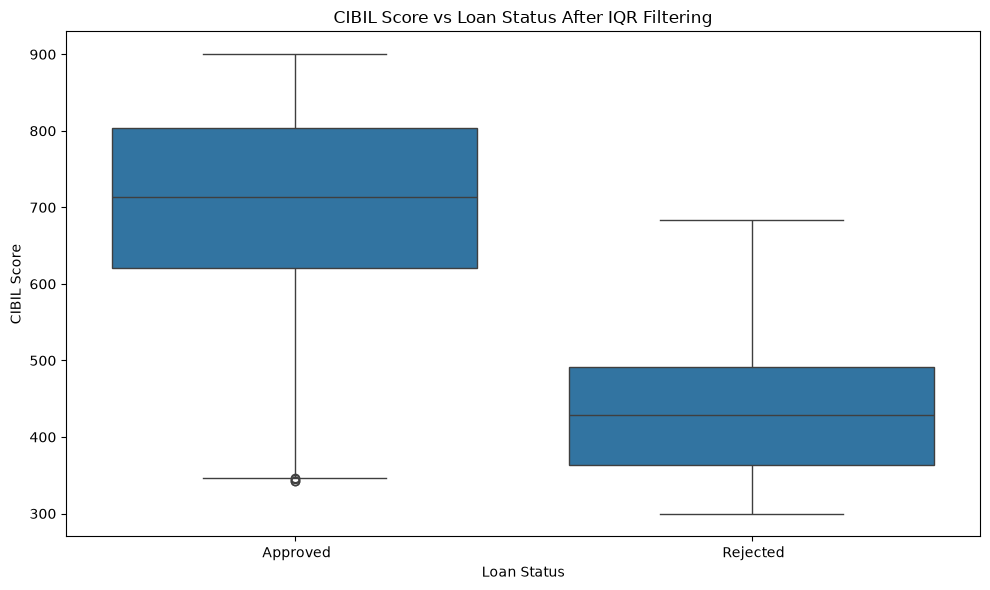

In [24]:

# Initialize the total number of potential outliers.
total_outliers = 0

# Create a Boolean mask to identify outliers.
outlier_mask = pd.Series(False, index=df.index)

# Check potential outliers separately for each loan status.
for status, group in df.groupby('loan_status'):

    # Calculate Q1 and Q3.
    Q1 = group['cibil_score'].quantile(0.25)
    Q3 = group['cibil_score'].quantile(0.75)

    # Calculate the interquartile range.
    IQR = Q3 - Q1

    # Calculate the lower and upper limits.
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Identify potential outliers within the group.
    group_outliers = (
        (group['cibil_score'] < lower_limit) |
        (group['cibil_score'] > upper_limit)
    )

    # Store the outlier flags for the corresponding rows.
    outlier_mask.loc[group.index] = group_outliers

    # Count the potential outliers in the group.
    count = group_outliers.sum()
    total_outliers += count

    # Display the results for each loan status.
    print("\nLoan status:", status)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of potential outliers:", count)

# Display the total number of potential outliers.
print("\nTotal number of potential outliers:", total_outliers)

# Create a filtered DataFrame, keeping the original df unchanged.
df_iqr = df.loc[~outlier_mask].copy()

# Compare the number of rows before and after filtering.
print("\nRows before filtering:", len(df))
print("Rows after filtering:", len(df_iqr))
print("Rows removed:", len(df) - len(df_iqr))

# Plot the CIBIL-score box plot after IQR filtering.
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_iqr, x='loan_status', y='cibil_score')

# Add the title and axis labels.
plt.title('CIBIL Score vs Loan Status After IQR Filtering')
plt.xlabel('Loan Status')
plt.ylabel('CIBIL Score')

# Display the final box plot.
plt.tight_layout()
plt.show()


In [25]:
# The IQR method identified 42 potential CIBIL-score outliers in the original dataset. After excluding these observations, 4,227 rows remained. 
# This analysis helps investigate extreme credit-score values. However, an IQR-flagged observation is not automatically incorrect, so the original 
# and filtered distributions should be compared before deciding whether removal is appropriate.

Original rows: 4269
Rows after iterative IQR filtering: 4221


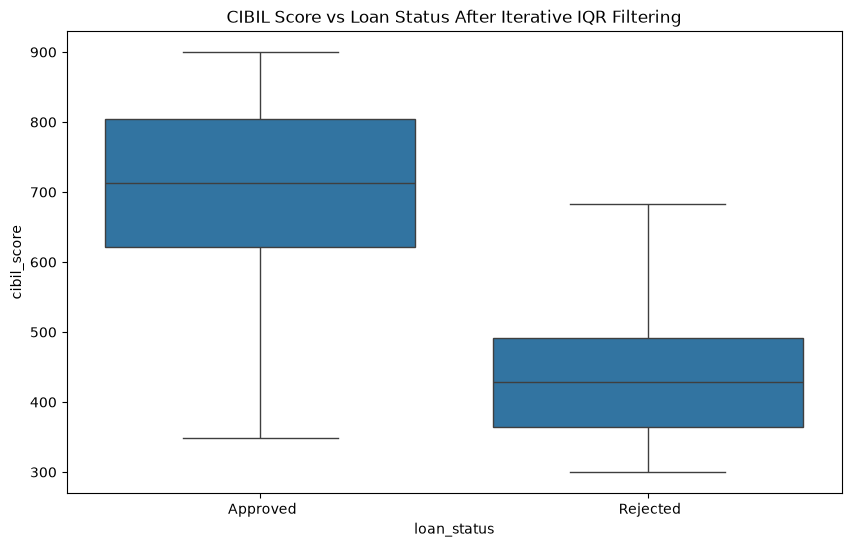

In [26]:

# Start with a copy of the original dataset.
df_iqr = df.copy()

# Repeat IQR filtering until no group-wise outliers remain.
while True:
    outlier_mask = pd.Series(False, index=df_iqr.index)

    # Calculate IQR limits separately for each loan status.
    for status, group in df_iqr.groupby('loan_status'):
        Q1 = group['cibil_score'].quantile(0.25)
        Q3 = group['cibil_score'].quantile(0.75)
        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        # Flag values outside the current group's limits.
        group_outliers = (
            (group['cibil_score'] < lower_limit) |
            (group['cibil_score'] > upper_limit)
        )

        outlier_mask.loc[group.index] = group_outliers

    # Stop when no more outliers are detected.
    if not outlier_mask.any():
        break

    # Remove the currently flagged rows.
    df_iqr = df_iqr.loc[~outlier_mask].copy()

# Display the number of rows remaining.
print("Original rows:", len(df))
print("Rows after iterative IQR filtering:", len(df_iqr))

# Plot the final box plot.
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_iqr, x='loan_status', y='cibil_score')
plt.title('CIBIL Score vs Loan Status After Iterative IQR Filtering')
plt.show()


In [27]:
# Coclusion after Iterative IQR Handling
# Iterative IQR filtering reduced the dataset from 4,269 to 4,221 rows, removing 48 observations in total. 
# The final box plot shows the distribution of CIBIL scores after repeated outlier removal using the IQR method.

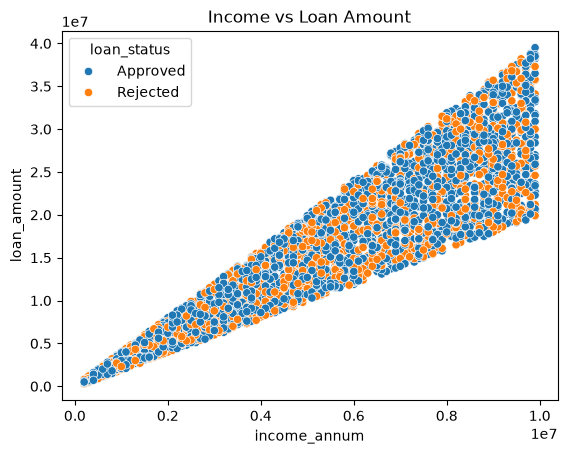

In [28]:
sns.scatterplot(
    data=df, x='income_annum',
    y='loan_amount', hue='loan_status'
)
plt.title('Income vs Loan Amount')
plt.show()

In [29]:
# Conclusion of scatter plot-:

# The scatter plot illustrates the relationship between applicants' annual income and requested loan amount. The points show a strong positive 
# relationship: applicants with higher annual incomes generally tend to request larger loans. The two colours allow us to compare approved and
# rejected applications at different income and loan-amount levels. However, income alone does not determine loan approval.

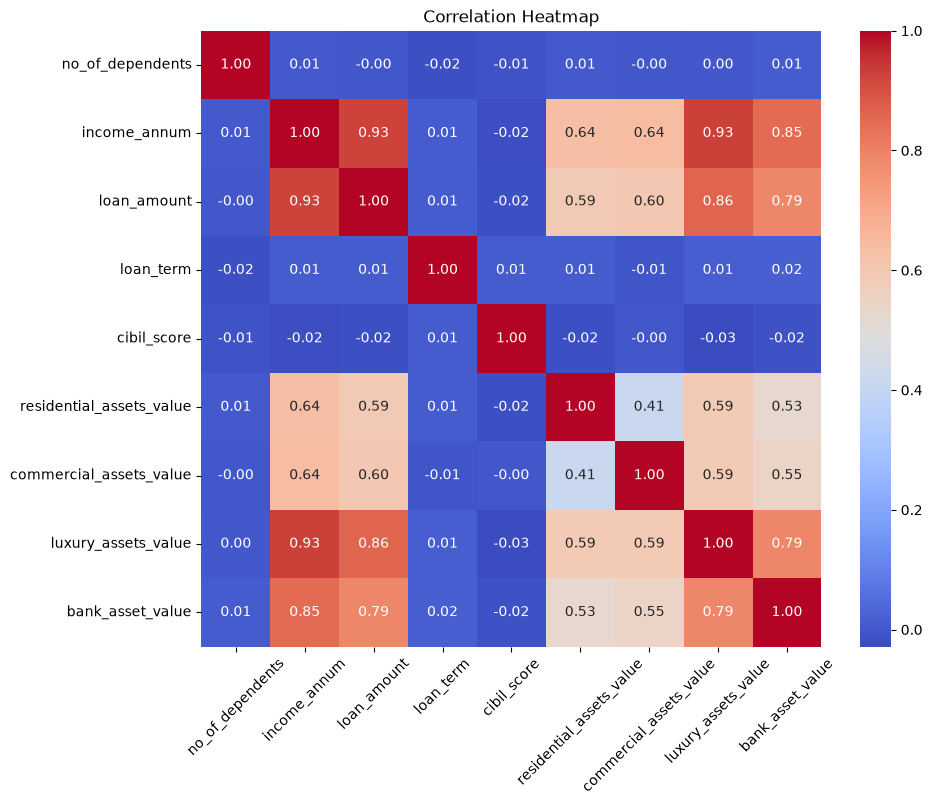

In [30]:
corr = numcols.drop(columns=['loan_id'], errors='ignore').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.xticks(rotation=45)
plt.show()

In [31]:
# Conclusion of heatmap-:

# The correlation heatmap shows the strength and direction of linear relationships between numerical variables. 
# Annual income and loan amount have a strong positive correlation of approximately 0.93. Annual income also shows positive correlations 
# with several asset-value variables. In contrast, CIBIL score has relatively weak linear correlations with most of the other numerical features. 
# Correlation does not imply causation, and these values alone cannot establish which factors determine loan approval.